# Lab 3 – Digital filtering: FIR, IIR and adaptive LMS filters for noise reduction
### All 16 variants of the instructions applied to the same noisy sinusoid

| | |
|---|---|
| **Author** | Radosław Skrzypczyński — Informatyka II st., niestacjonarne, 1 sem., Gr. 2 |
| **Course** | Digital Signal Processing — prof. dr hab. Vasyl Martsenyuk |
| **Repository** | https://github.com/Slayzerus/dsp-lab3 |

**Task (Sec. 7 of the instructions "5. Digital Filter Design and Analysis … 6. Adaptive Filtering").** Each task
requires implementing all three types of filters — FIR, IIR and adaptive LMS — with the parameters of the variant,
applying them to the same noisy sinusoidal signal and observing their performance for noise reduction.
**All 16 variants are computed.**

**Contents.** 1 Theory · 2 Implementation and validation · 3 Test signal · 4 Variants · 5 Results per variant ·
6 Comparison of all variants · 7 Interpretation · 8 Conclusions

In [1]:
import platform
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager
from scipy.signal import lfilter, freqz
from IPython.display import display

print(f"Python {platform.python_version()} | numpy {np.__version__} | scipy {scipy.__version__} | "
      f"matplotlib {matplotlib.__version__} | pandas {pd.__version__}")

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
pd.options.display.precision = 3
pd.options.display.width = 200

Python 3.14.2 | numpy 2.4.1 | scipy 1.18.1 | matplotlib 3.10.8 | pandas 3.0.6


## 1. Theory

* **FIR filter** (Sec. 2): y[n] = Σₖ bₖ·x[n − k], H(z) = Σₘ bₘ·z⁻ᵐ. No feedback, always stable; linear phase
  for symmetric coefficients.
* **IIR filter** (Sec. 3): y[n] = Σₖ bₖ·x[n − k] − Σₖ₌₁ aₖ·y[n − k], H(z) = B(z)/A(z) with a₀ = 1. The feedback
  gives an infinite impulse response; the filter is stable if all poles (roots of A) lie inside the unit circle.
* **LMS adaptive filter** (Sec. 4): an M-tap FIR filter whose weights minimise the mean squared error
  J(w) = E[(d[n] − wᵀx[n])²]. With the input vector x[n] = (x[n], x[n−1], …, x[n−M+1])ᵀ:
  y[n] = wᵀ[n]·x[n], e[n] = d[n] − y[n], **w[n+1] = w[n] + μ·e[n]·x[n]**. It converges (in the mean) for
  0 < μ < 2/λ_max, λ_max = largest eigenvalue of R = E[x[n]x[n]ᵀ], towards the Wiener solution w_opt = R⁻¹p,
  p = E[d[n]x[n]].
* **Measuring noise reduction.** For an LTI filter and the input x = s + v (signal s, noise v), the output is
  h∗s + h∗v. For a sinusoid of frequency f₀ in white noise the SNR changes by
  **ΔSNR = 10·log₁₀(|H(f₀)|² / Σₙ h[n]²)** — the ratio of the signal gain to the white-noise power gain. ΔSNR
  does not depend on the overall gain or on the delay. In addition, the output is compared directly with the clean
  signal, MSE = mean((y − s)²), which also penalises a wrong gain and a delay (what one would actually see).

In [2]:
# Plot style: the same as in the other lab notebooks.
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
_fonts = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "figure.facecolor": "white", "axes.facecolor": "white",
    "font.family": [f for f in ("Segoe UI", "DejaVu Sans") if f in _fonts] or ["sans-serif"],
    "font.size": 9, "axes.titlesize": 9.5, "axes.titleweight": "semibold", "axes.titlelocation": "left",
    "axes.labelsize": 9, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-",
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "legend.frameon": False, "legend.fontsize": 8, "legend.labelcolor": INK2,
    "lines.linewidth": 1.5, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "mathtext.fontset": "dejavusans", "figure.titlesize": 10.5, "figure.titleweight": "semibold",
})
COL = {"FIR": "#2a78d6", "IIR": "#eb6834", "LMS": "#1baf7a"}     # fixed colour per filter type


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")
    plt.show()

## 2. Implementation and validation

The three filters are implemented directly from the difference equations with zero initial state. They follow the
code of Sec. 5 of the instructions, with three corrections:

* **FIR:** the loop of the instructions starts at n = M, so the first M output samples stay zero; here every
  sample is computed (missing past inputs are zero).
* **IIR:** in the instructions the slices `x[max(0, n-M+1):n+1]` and `y[max(0, n-N+1):n]` are shorter than `b`
  and `a[1:]` for the first samples, so `np.dot` fails for every filter with more than one coefficient (shown
  below); the coefficients are also normalised by a₀ here.
* **LMS:** the instructions use `x[i-num_taps:i]`, i.e. x[n−1] … x[n−M] without the current sample, although
  Sec. 4.1–4.2 define the input vector as the current and the previous M − 1 samples and e[n] = d[n] − wᵀ[n]x[n].
  Here x[n] = (x[n], …, x[n−M+1])ᵀ is used, as in the theory.

FIR and IIR are validated against `scipy.signal.lfilter`; the LMS filter is validated against the Wiener
solution computed from the same data (Section 5).

In [3]:
def fir_filter(x, b):
    """FIR filter y[n] = sum_k b[k] x[n-k] (zero initial state)."""
    x, b = np.asarray(x, float), np.asarray(b, float)
    M = b.size
    xp = np.concatenate([np.zeros(M - 1), x])           # x[n-k] = 0 for n-k < 0
    y = np.zeros(x.size)
    for n in range(x.size):
        y[n] = np.dot(b, xp[n:n + M][::-1])              # b0 x[n] + b1 x[n-1] + ...
    return y


def iir_filter(x, b, a):
    """IIR filter y[n] = sum_k b[k] x[n-k] - sum_{k>=1} a[k] y[n-k] (zero initial state)."""
    x = np.asarray(x, float)
    b, a = np.asarray(b, float)/a[0], np.asarray(a, float)/a[0]
    M, N = b.size, a.size
    xp = np.concatenate([np.zeros(M - 1), x])
    yp = np.zeros(N - 1 + x.size)                         # N-1 zeros = y[-1], y[-2], ... before the start
    for n in range(x.size):
        acc = np.dot(b, xp[n:n + M][::-1])
        if N > 1:
            acc -= np.dot(a[1:], yp[n:n + N - 1][::-1])  # a1 y[n-1] + a2 y[n-2] + ...
        yp[n + N - 1] = acc
    return yp[N - 1:]


def lms_filter(x, d, mu, M):
    """LMS adaptive filter: y = w^T x[n], e = d - y, w <- w + mu e x[n], x[n] = (x[n], ..., x[n-M+1])."""
    x, d = np.asarray(x, float), np.asarray(d, float)
    xp = np.concatenate([np.zeros(M - 1), x])
    w = np.zeros(M)
    y, e = np.zeros(x.size), np.zeros(x.size)
    W = np.zeros((x.size, M))                             # weight history
    for n in range(x.size):
        u = xp[n:n + M][::-1]
        y[n] = w @ u
        e[n] = d[n] - y[n]
        w = w + mu*e[n]*u
        W[n] = w
    return y, e, w, W


def tap_matrix(x, M):
    """Rows x[n] = (x[n], ..., x[n-M+1]) for all n (zero initial state)."""
    xp = np.concatenate([np.zeros(M - 1), np.asarray(x, float)])
    return np.stack([xp[n:n + M][::-1] for n in range(len(x))])


# validation against scipy with a random signal and random coefficients
rng_val = np.random.default_rng(1)
xv = rng_val.standard_normal(500)
for b, a in (([0.2, 0.3, 0.2], [1.0]), ([1, -1.5, 0.7], [1, 0.5, 0.1]), ([0.4, 0.3], [2, -1.0]),
             (rng_val.standard_normal(7), [1, -0.9, 0.2])):
    if len(a) == 1:
        assert np.allclose(fir_filter(xv, b), lfilter(b, a, xv))
    assert np.allclose(iir_filter(xv, b, a), lfilter(b, a, xv))
print("fir_filter and iir_filter agree with scipy.signal.lfilter: OK")

fir_filter and iir_filter agree with scipy.signal.lfilter: OK


In [4]:
# The IIR code of the instructions (Sec. 5.2), unchanged, fails on the first samples:
def iir_filter_instructions(x, b, a):
    M = len(b)
    N = len(a)
    y = np.zeros(len(x))
    for n in range(len(x)):
        y[n] = np.dot(b, x[max(0, n-M+1):n+1][::-1])
        if n > 0:
            y[n] -= np.dot(a[1:], y[max(0, n-N+1):n][::-1])
    return y


try:
    iir_filter_instructions(xv, [0.1, 0.2, 0.3], [1, -0.5, 0.1])
except ValueError as err:
    print("iir_filter of the instructions:", type(err).__name__, "-", err)

iir_filter of the instructions: ValueError - shapes (3,) and (1,) not aligned: 3 (dim 0) != 1 (dim 0)


## 3. Test signal

As in the examples of the instructions: a sinusoid of f₀ = 5 Hz and amplitude 1, sampled with fₛ = 1000 Hz for
1 s (N = 1000), plus white Gaussian noise of standard deviation σ = 0.5 (fixed seed). The same signal is used
for all variants, so the results are directly comparable. The nominal input SNR is 10·log₁₀(0.5/0.25) ≈ 3 dB;
all metrics below are evaluated in the second half of the record (n ≥ 500), after the filter transients and
the convergence of the LMS filter.

whole record: signal power 0.500, noise power 0.266, SNR = 2.75 dB
second half (reference for all metrics): MSE(x, s) = 0.2569, input SNR = 2.89 dB


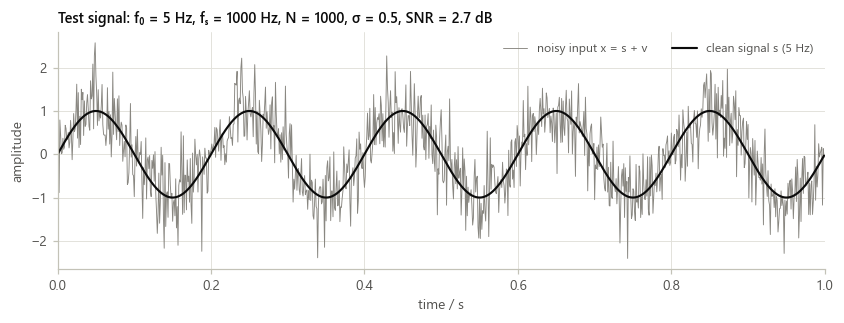

In [5]:
FS, F0, N_SAMPLES, SIGMA = 1000, 5.0, 1000, 0.5
t = np.arange(N_SAMPLES)/FS
s = np.sin(2*np.pi*F0*t)                                  # clean signal (also the desired signal d of LMS)
v = SIGMA*np.random.default_rng(2026).standard_normal(N_SAMPLES)
x = s + v                                                 # noisy input
SS = N_SAMPLES//2                                         # metrics: second half (after transients/convergence)


def snr_db(sig, err):
    return 10*np.log10(np.mean(sig**2)/np.mean(err**2))


SNR_IN = snr_db(s[SS:], v[SS:])                           # reference: input SNR in the evaluated part
MSE_IN = np.mean(v[SS:]**2)
print(f"whole record: signal power {np.mean(s**2):.3f}, noise power {np.mean(v**2):.3f}, "
      f"SNR = {snr_db(s, v):.2f} dB")
print(f"second half (reference for all metrics): MSE(x, s) = {MSE_IN:.4f}, input SNR = {SNR_IN:.2f} dB")

fig, ax = plt.subplots(figsize=(9, 2.8))
ax.plot(t, x, color=MUTED, lw=0.6, label="noisy input x = s + v")
ax.plot(t, s, color=INK, lw=1.4, label="clean signal s (5 Hz)")
ax.set(xlabel="time / s", ylabel="amplitude", xlim=(0, 1))
ax.set_title(f"Test signal: f₀ = 5 Hz, fₛ = 1000 Hz, N = 1000, σ = 0.5, SNR = {snr_db(s, v):.1f} dB")
ax.legend(loc="upper right", ncols=2)
save(fig, "fig01_test_signal")

## 4. Variants

The parameters of the 16 variants (Sec. 7 of the instructions). In the IIR filters a = {1, a₁, a₂} denotes
A(z) = 1 + a₁z⁻¹ + a₂z⁻², with the sign convention of Sec. 3 (and of `scipy.signal.lfilter`).

In [6]:
VARIANTS = {
    1: dict(b_fir=[0, 0, 1], b_iir=[1, -1.5, 0.7], a_iir=[1, 0.5, 0.1], mu=0.01, M=4),
    2: dict(b_fir=[1, 1, 2], b_iir=[0.5, 0.2], a_iir=[1, -0.8], mu=0.05, M=4),
    3: dict(b_fir=[0, 0, 3], b_iir=[0.6, 0.3, 0.1], a_iir=[1, 0.5, 0.2], mu=0.01, M=6),
    4: dict(b_fir=[0.2, 0.3, 0.2], b_iir=[1, 0.5, 0.3], a_iir=[1, -0.6], mu=0.1, M=4),
    5: dict(b_fir=[0.5, 0.3, 0.1], b_iir=[0.3, 0.4, 0.3], a_iir=[1, -0.4, 0.2], mu=0.05, M=4),
    6: dict(b_fir=[0.25, 0.25, 0.25, 0.25], b_iir=[1, 1, 1], a_iir=[1, -0.5], mu=0.1, M=6),
    7: dict(b_fir=[1, -1, 0.5], b_iir=[0.3, 0.4], a_iir=[1, -0.5, 0.2], mu=0.05, M=4),
    8: dict(b_fir=[1, 0, 1], b_iir=[0.5, 0.5], a_iir=[1, -0.3], mu=0.05, M=5),
    9: dict(b_fir=[0, 1, 0], b_iir=[0.2, 0.8], a_iir=[1, 0.5], mu=0.05, M=3),
    10: dict(b_fir=[0.4, 0.4, 0.4], b_iir=[1, -0.6], a_iir=[1, 0.5], mu=0.1, M=5),
    11: dict(b_fir=[1, -0.2, 0.5], b_iir=[0.6, 0.3], a_iir=[1, 0.4], mu=0.05, M=6),
    12: dict(b_fir=[1, 0, -1], b_iir=[0.4, 0.6], a_iir=[1, -0.3], mu=0.02, M=5),
    13: dict(b_fir=[1, 0.5, 0.5], b_iir=[1, -0.5, 0.2], a_iir=[1, -0.3], mu=0.1, M=4),
    14: dict(b_fir=[0.5, 0.5], b_iir=[0.3, 0.4], a_iir=[1, -0.4], mu=0.1, M=3),
    15: dict(b_fir=[0.2, 0.3, 0.5], b_iir=[1, 0.5], a_iir=[1, -0.7], mu=0.05, M=6),
    16: dict(b_fir=[0.5, 0.5], b_iir=[0.4, 0.3], a_iir=[1, -0.5], mu=0.05, M=5),
}


def fmt(c):
    return "{" + ", ".join(f"{v:g}" for v in c) + "}"


display(pd.DataFrame({no: {"FIR b": fmt(p["b_fir"]), "IIR b": fmt(p["b_iir"]), "IIR a": fmt(p["a_iir"]),
                           "LMS μ": p["mu"], "LMS M": p["M"]} for no, p in VARIANTS.items()}).T.rename_axis("No"))

,FIR b,IIR b,IIR a,LMS μ,LMS M
No,,,,,
1,"{0, 0, 1}","{1, -1.5, 0.7}","{1, 0.5, 0.1}",0.01,4
2,"{1, 1, 2}","{0.5, 0.2}","{1, -0.8}",0.05,4
3,"{0, 0, 3}","{0.6, 0.3, 0.1}","{1, 0.5, 0.2}",0.01,6
4,"{0.2, 0.3, 0.2}","{1, 0.5, 0.3}","{1, -0.6}",0.1,4
5,"{0.5, 0.3, 0.1}","{0.3, 0.4, 0.3}","{1, -0.4, 0.2}",0.05,4
6,"{0.25, 0.25, 0.25, 0.25}","{1, 1, 1}","{1, -0.5}",0.1,6
7,"{1, -1, 0.5}","{0.3, 0.4}","{1, -0.5, 0.2}",0.05,4
8,"{1, 0, 1}","{0.5, 0.5}","{1, -0.3}",0.05,5
9,"{0, 1, 0}","{0.2, 0.8}","{1, 0.5}",0.05,3


## 5. Results per variant

For every variant the three filters are applied to the test signal. Metrics:

* **|H(f₀)|, |H(0)|, |H(fₛ/2)|** — gain at the signal frequency, at DC and at the Nyquist frequency, and the
  resulting filter type (low-pass, high-pass, band-pass, band-stop, all-pass = pure gain/delay);
* **noise gain Σh²** and **ΔSNR** (theory, white noise) and **ΔSNR measured** — s and v are filtered separately
  (the filters are linear) and the output SNR is measured;
* **MSE(y, s)** and **SNR re s** = 10·log₁₀(P_s / MSE) — direct comparison with the clean signal (input:
  MSE(x, s) = 0.257, SNR = 2.89 dB). All measured values refer to the second half of the record;
* **IIR stability:** largest pole radius; **LMS:** μ_max = 2/λ_max, Wiener MSE, final weights.

In [7]:
def filter_type(b, a):
    _, H = freqz(b, a, worN=[0.0, FS/4, FS/2], fs=FS)
    g0, g4, g2 = np.abs(H)
    if max(g0, g4, g2) - min(g0, g4, g2) < 1e-9*max(g0, g4, g2, 1):
        return "all-pass (gain/delay)"
    if g0 >= g4 and g0 >= g2:
        return "low-pass"
    if g2 >= g4 and g2 >= g0:
        return "high-pass"
    if g4 >= g0 and g4 >= g2:
        return "band-pass"
    return "band-stop"


def lti_metrics(b, a, filt):
    """Frequency-domain and measured metrics of an LTI filter; filt(x) applies it."""
    _, H = freqz(b, a, worN=[F0, 0.0, FS/2], fs=FS)
    imp = np.zeros(4096)
    imp[0] = 1
    h = lfilter(b, a, imp)
    y, ys, yv = filt(x), filt(s), filt(v)
    k = slice(SS, None)
    return dict(type=filter_type(b, a), H_f0=abs(H[0]), H_dc=abs(H[1]), H_nyq=abs(H[2]),
                noise_gain=np.sum(h**2), dSNR_theory=10*np.log10(abs(H[0])**2/np.sum(h**2)),
                dSNR_meas=snr_db(ys[k], yv[k]) - snr_db(s[k], v[k]),
                MSE=np.mean((y[k] - s[k])**2), SNR_re_s=snr_db(s[k], y[k] - s[k]), y=y)


RES = {}
for no, p in VARIANTS.items():
    fir = lti_metrics(p["b_fir"], [1.0], lambda z, b=p["b_fir"]: fir_filter(z, b))
    iir = lti_metrics(p["b_iir"], p["a_iir"], lambda z, b=p["b_iir"], a=p["a_iir"]: iir_filter(z, b, a))
    iir["pole_radius"] = np.max(np.abs(np.roots(p["a_iir"])))
    y_l, e_l, w_l, W_l = lms_filter(x, s, p["mu"], p["M"])
    U = tap_matrix(x, p["M"])
    R, pv = U.T @ U/N_SAMPLES, U.T @ s/N_SAMPLES
    w_opt = np.linalg.solve(R, pv)
    lam_max = np.linalg.eigvalsh(R).max()
    k = slice(SS, None)
    lms = dict(y=y_l, e=e_l, w=w_l, W=W_l, w_opt=w_opt, mu_max=2/lam_max, lam_max=lam_max,
               MSE=np.mean((y_l[k] - s[k])**2), SNR_re_s=snr_db(s[k], y_l[k] - s[k]),
               MSE_wiener=np.mean((U[k] @ w_opt - s[k])**2))
    RES[no] = dict(FIR=fir, IIR=iir, LMS=lms)

# sanity checks
for no, r in RES.items():
    assert abs(r["FIR"]["dSNR_theory"] - r["FIR"]["dSNR_meas"]) < 1.5           # theory ~ measurement
    assert abs(r["IIR"]["dSNR_theory"] - r["IIR"]["dSNR_meas"]) < 1.5
    assert r["IIR"]["pole_radius"] < 1                                          # all IIR filters stable
    assert VARIANTS[no]["mu"] < r["LMS"]["mu_max"]                              # LMS step sizes admissible
print("ΔSNR theory ≈ measurement, all IIR filters stable, all LMS step sizes below 2/λ_max: OK")

ΔSNR theory ≈ measurement, all IIR filters stable, all LMS step sizes below 2/λ_max: OK


In [8]:
def plot_variant(no):
    p, r = VARIANTS[no], RES[no]
    fig = plt.figure(figsize=(10.5, 6.2))
    gs = fig.add_gridspec(2, 3, height_ratios=[1, 1], hspace=0.45, wspace=0.28)
    labels = {"FIR": f"FIR b = {fmt(p['b_fir'])}",
              "IIR": f"IIR b = {fmt(p['b_iir'])}, a = {fmt(p['a_iir'])}",
              "LMS": f"LMS μ = {p['mu']:g}, M = {p['M']}"}
    for c, key in enumerate(("FIR", "IIR", "LMS")):
        ax = fig.add_subplot(gs[0, c])
        ax.plot(t, x, color=GRID, lw=0.6, label="noisy x")
        ax.plot(t, s, color=INK, lw=1.0, ls="--", label="clean s")
        ax.plot(t, r[key]["y"], color=COL[key], lw=1.0, label="output y")
        snr = r[key]["SNR_re_s"]
        ax.set_title(labels[key], fontsize=8.3)
        ax.text(0.02, 0.03, f"SNR re s = {snr:.1f} dB (input {SNR_IN:.1f} dB)",
                transform=ax.transAxes, fontsize=7.5, color=INK2)
        ax.set_xlabel("time / s")
        ax.set_xlim(0, 1)
        if c == 0:
            ax.set_ylabel("amplitude")
            ax.legend(loc="upper right", fontsize=7, ncols=3)
    # magnitude responses
    ax = fig.add_subplot(gs[1, 0])
    fgrid = np.logspace(0, np.log10(FS/2), 600)
    for key, (b, a) in (("FIR", (p["b_fir"], [1.0])), ("IIR", (p["b_iir"], p["a_iir"])),
                        ("LMS", (r["LMS"]["w"], [1.0]))):
        _, H = freqz(b, a, worN=fgrid, fs=FS)
        ax.semilogx(fgrid, 20*np.log10(np.maximum(np.abs(H), 1e-6)), color=COL[key], lw=1.3,
                    label=key + (" (final w)" if key == "LMS" else ""))
    ax.axvline(F0, color=MUTED, lw=0.8, ls=":")
    ax.set(xlabel="frequency / Hz", ylabel="|H(f)| / dB", xlim=(1, FS/2))
    ax.set_ylim(max(ax.get_ylim()[0], -60), ax.get_ylim()[1] + 3)
    ax.set_title("Magnitude responses (dotted: f₀ = 5 Hz)", fontsize=8.3)
    ax.legend(loc="lower left", fontsize=7)
    # pole-zero plot of the IIR filter
    ax = fig.add_subplot(gs[1, 1])
    th = np.linspace(0, 2*np.pi, 400)
    ax.plot(np.cos(th), np.sin(th), color=AXIS, lw=0.8)
    z, pl = np.roots(p["b_iir"]), np.roots(p["a_iir"])
    ax.plot(z.real, z.imag, "o", mfc="white", mec=COL["IIR"], ms=7, mew=1.3)
    ax.plot(pl.real, pl.imag, "x", color=COL["IIR"], ms=8, mew=1.6)
    lim = max(1.15, np.abs(np.concatenate([z, pl])).max()*1.15) if z.size or pl.size else 1.15
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), aspect="equal", xlabel="Re z", ylabel="Im z")
    ax.set_title(f"IIR poles × / zeros ○ (max |p| = {r['IIR']['pole_radius']:.2f})", fontsize=8.3)
    # LMS learning curve
    ax = fig.add_subplot(gs[1, 2])
    sm = np.convolve(r["LMS"]["e"]**2, np.ones(25)/25, mode="same")
    ax.semilogy(t, sm, color=COL["LMS"], lw=1.0, label="e²[n] (25-sample mean)")
    ax.axhline(MSE_IN, color=MUTED, lw=0.9, ls="--", label="input noise power")
    ax.axhline(r["LMS"]["MSE_wiener"], color=INK, lw=0.9, ls=":", label="Wiener MSE")
    ax.set(xlabel="time / s", ylabel="squared error", xlim=(0, 1))
    ax.set_title(f"LMS learning curve (μ_max = 2/λ_max = {r['LMS']['mu_max']:.2f})", fontsize=8.3)
    ax.legend(loc="upper right", fontsize=7)
    fig.suptitle(f"Variant {no}", x=0.01, ha="left")
    save(fig, f"fig{1 + no:02d}_variant_{no:02d}")


def variant_table(no):
    r = RES[no]
    rows = {}
    for key in ("FIR", "IIR"):
        m = r[key]
        rows[key] = {"type": m["type"], "|H(f₀)|": m["H_f0"], "|H(0)|": m["H_dc"], "|H(fs/2)|": m["H_nyq"],
                     "noise gain Σh²": m["noise_gain"], "ΔSNR theory [dB]": m["dSNR_theory"],
                     "ΔSNR measured [dB]": m["dSNR_meas"], "MSE(y, s)": m["MSE"], "SNR re s [dB]": m["SNR_re_s"]}
    rows["IIR"]["type"] += f", max|p| = {r['IIR']['pole_radius']:.2f}"
    lm = r["LMS"]
    rows["LMS"] = {"type": f"adaptive, M = {VARIANTS[no]['M']}, μ = {VARIANTS[no]['mu']:g}",
                   "MSE(y, s)": lm["MSE"], "SNR re s [dB]": lm["SNR_re_s"]}
    display(pd.DataFrame(rows).T.fillna("").rename_axis(f"variant {no}"))
    print(f"LMS: final w = {np.round(lm['w'], 3)},  Wiener w_opt = {np.round(lm['w_opt'], 3)},  "
          f"MSE {lm['MSE']:.4f} vs Wiener {lm['MSE_wiener']:.4f},  μ = {VARIANTS[no]['mu']:g} < μ_max = "
          f"{lm['mu_max']:.3f}")

### 5.1 Variant 1

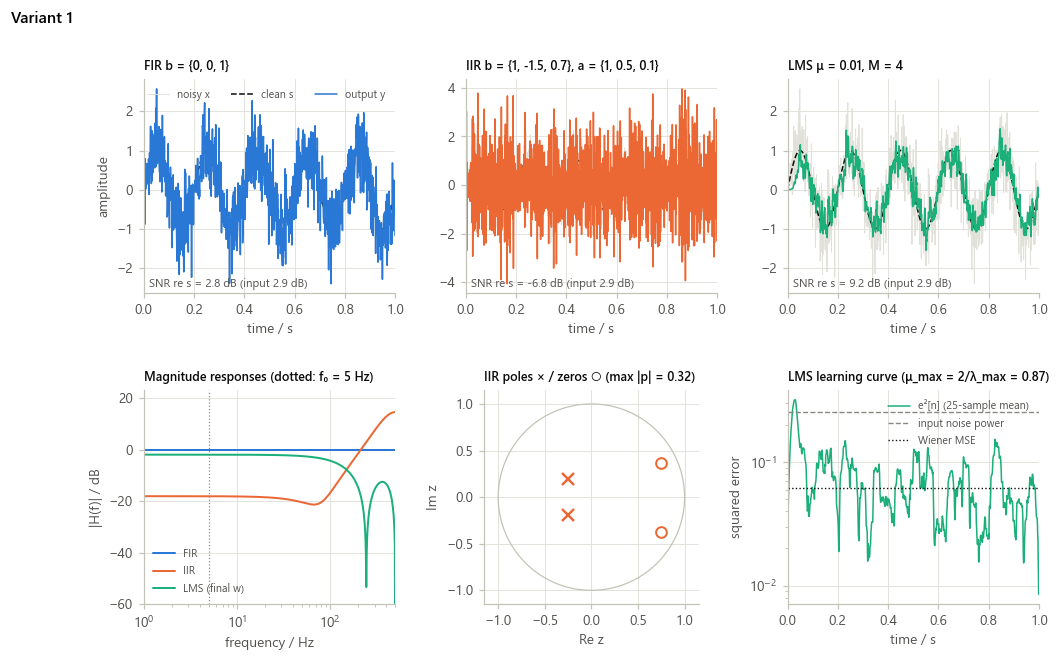

,type,|H(f₀)|,|H(0)|,|H(fs/2)|,noise gain Σh²,ΔSNR theory [dB],ΔSNR measured [dB],"MSE(y, s)",SNR re s [dB]
variant 1,,,,,,,,,
FIR,all-pass (gain/delay),1.0,1.0,1.0,1.0,0.0,-0.02,0.263,2.791
IIR,"high-pass, max|p| = 0.32",0.125,0.125,5.333,7.94,-27.085,-27.057,2.411,-6.832
LMS,"adaptive, M = 4, μ = 0.01",,,,,,,0.061,9.155


LMS: final w = [0.208 0.193 0.192 0.206],  Wiener w_opt = [0.231 0.21  0.207 0.224],  MSE 0.0607 vs Wiener 0.0622,  μ = 0.01 < μ_max = 0.872


In [9]:
plot_variant(1)
variant_table(1)

### 5.2 Variant 2

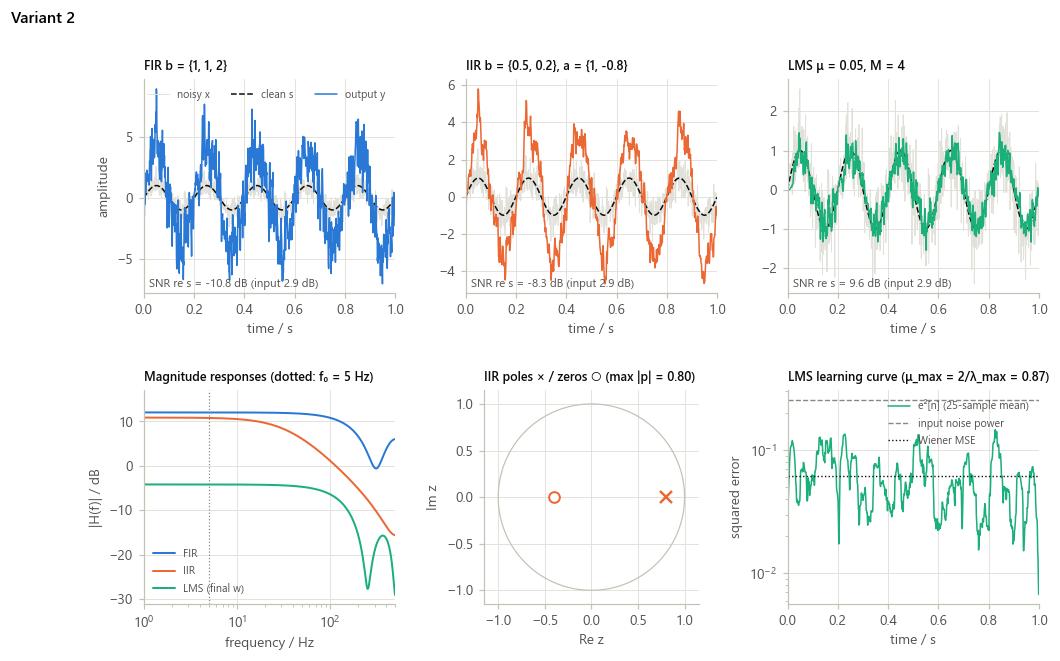

,type,|H(f₀)|,|H(0)|,|H(fs/2)|,noise gain Σh²,ΔSNR theory [dB],ΔSNR measured [dB],"MSE(y, s)",SNR re s [dB]
variant 2,,,,,,,,,
FIR,low-pass,3.999,4.0,2.0,6.0,4.257,4.112,5.991,-10.785
IIR,"low-pass, max|p| = 0.80",3.466,3.5,0.167,1.25,9.827,9.587,3.349,-8.259
LMS,"adaptive, M = 4, μ = 0.05",,,,,,,0.055,9.553


LMS: final w = [0.13  0.15  0.162 0.177],  Wiener w_opt = [0.231 0.21  0.207 0.224],  MSE 0.0554 vs Wiener 0.0622,  μ = 0.05 < μ_max = 0.872


In [10]:
plot_variant(2)
variant_table(2)

### 5.3 Variant 3

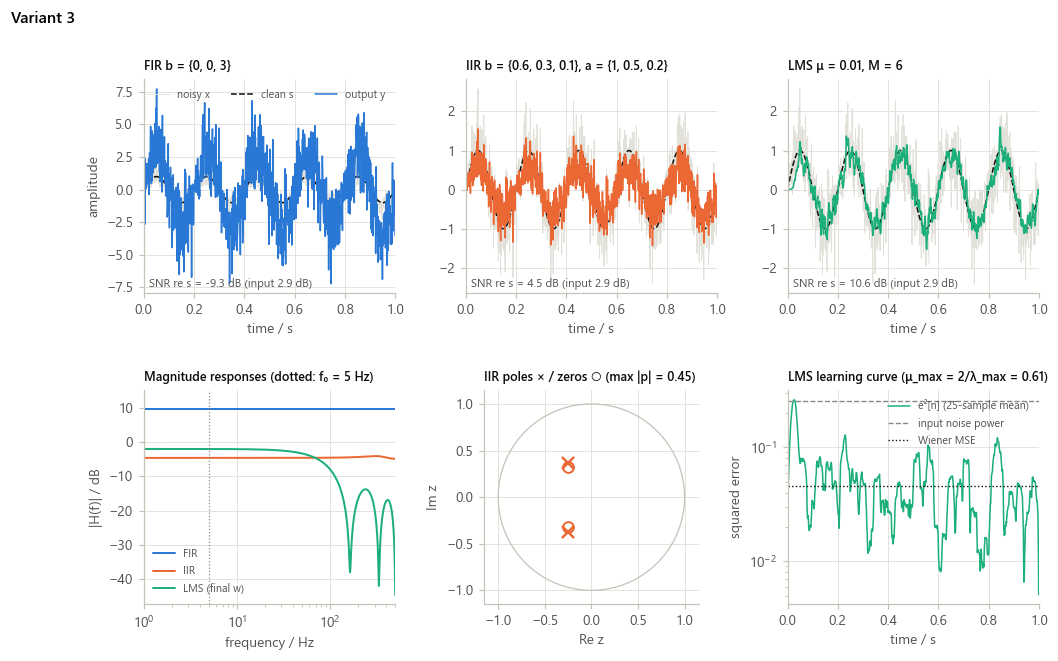

,type,|H(f₀)|,|H(0)|,|H(fs/2)|,noise gain Σh²,ΔSNR theory [dB],ΔSNR measured [dB],"MSE(y, s)",SNR re s [dB]
variant 3,,,,,,,,,
FIR,all-pass (gain/delay),3.0,3.0,3.0,9.0,0.0,-0.02,4.284,-9.329
IIR,"band-pass, max|p| = 0.45",0.588,0.588,0.571,0.361,-0.178,-0.17,0.179,4.451
LMS,"adaptive, M = 6, μ = 0.01",,,,,,,0.043,10.648


LMS: final w = [0.142 0.136 0.128 0.127 0.13  0.132],  Wiener w_opt = [0.171 0.159 0.143 0.14  0.148 0.151],  MSE 0.0431 vs Wiener 0.0459,  μ = 0.01 < μ_max = 0.610


In [11]:
plot_variant(3)
variant_table(3)

### 5.4 Variant 4

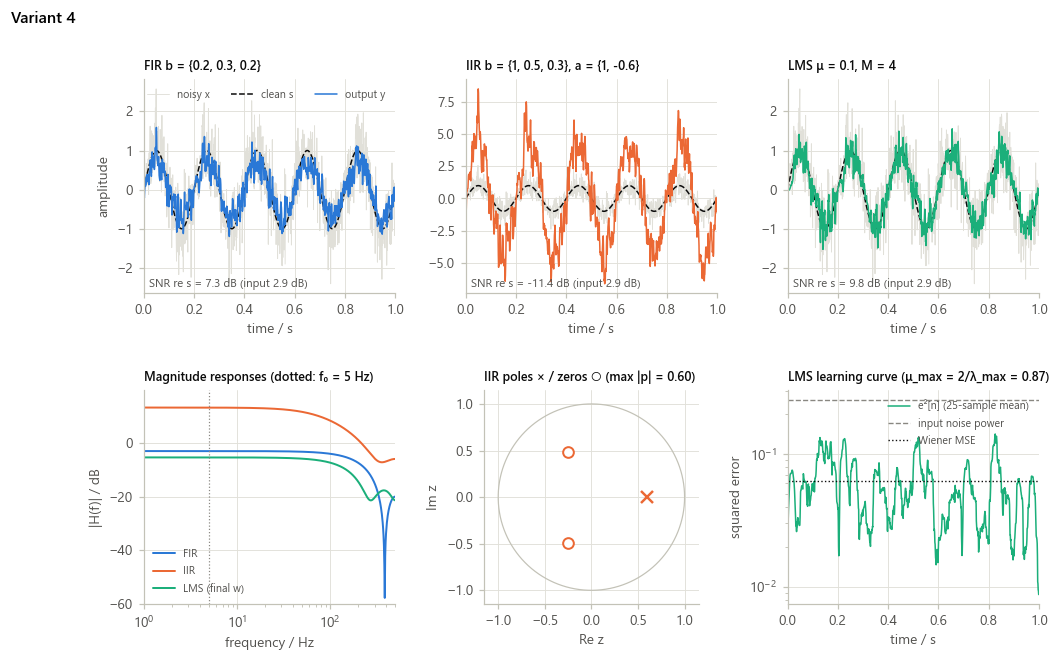

,type,|H(f₀)|,|H(0)|,|H(fs/2)|,noise gain Σh²,ΔSNR theory [dB],ΔSNR measured [dB],"MSE(y, s)",SNR re s [dB]
variant 4,,,,,,,,,
FIR,low-pass,0.7,0.7,0.1,0.17,4.595,4.438,0.094,7.279
IIR,"low-pass, max|p| = 0.60",4.49,4.5,0.5,3.65,7.423,7.292,6.936,-11.421
LMS,"adaptive, M = 4, μ = 0.1",,,,,,,0.052,9.828


LMS: final w = [0.072 0.127 0.152 0.183],  Wiener w_opt = [0.231 0.21  0.207 0.224],  MSE 0.0520 vs Wiener 0.0622,  μ = 0.1 < μ_max = 0.872


In [12]:
plot_variant(4)
variant_table(4)

### 5.5 Variant 5

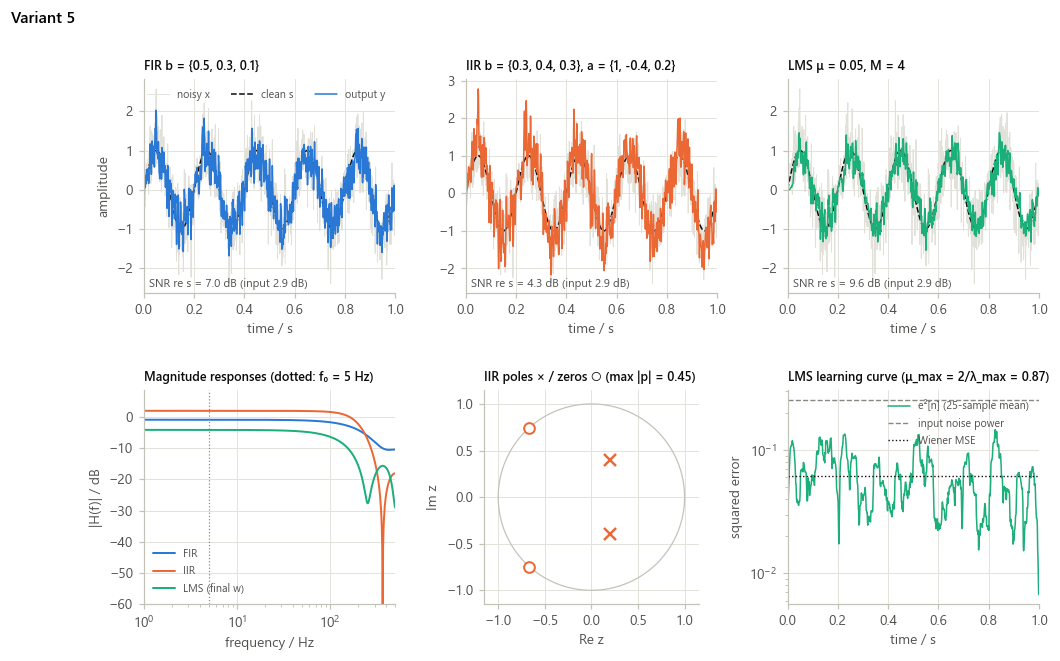

,type,|H(f₀)|,|H(0)|,|H(fs/2)|,noise gain Σh²,ΔSNR theory [dB],ΔSNR measured [dB],"MSE(y, s)",SNR re s [dB]
variant 5,,,,,,,,,
FIR,low-pass,0.9,0.9,0.3,0.35,3.642,3.539,0.099,7.046
IIR,"low-pass, max|p| = 0.45",1.25,1.25,0.125,0.572,4.365,4.163,0.185,4.327
LMS,"adaptive, M = 4, μ = 0.05",,,,,,,0.055,9.553


LMS: final w = [0.13  0.15  0.162 0.177],  Wiener w_opt = [0.231 0.21  0.207 0.224],  MSE 0.0554 vs Wiener 0.0622,  μ = 0.05 < μ_max = 0.872


In [13]:
plot_variant(5)
variant_table(5)

### 5.6 Variant 6

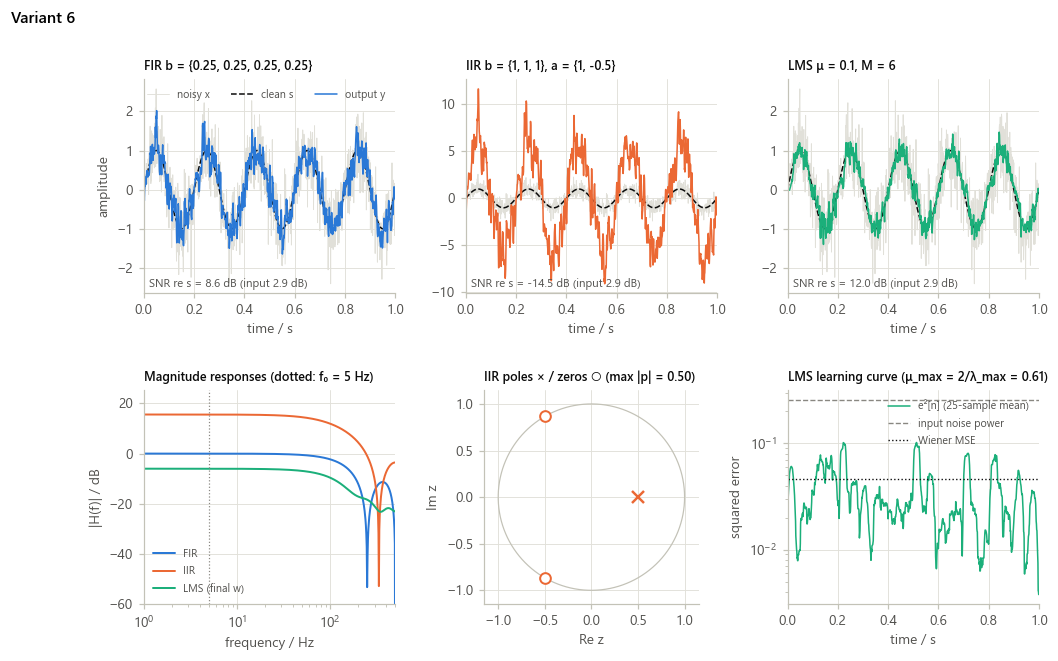

,type,|H(f₀)|,|H(0)|,|H(fs/2)|,noise gain Σh²,ΔSNR theory [dB],ΔSNR measured [dB],"MSE(y, s)",SNR re s [dB]
variant 6,,,,,,,,,
FIR,low-pass,0.999,1.0,0.0,0.25,6.015,5.892,0.069,8.591
IIR,"low-pass, max|p| = 0.50",5.992,6.0,0.667,7.333,6.899,6.764,14.157,-14.52
LMS,"adaptive, M = 6, μ = 0.1",,,,,,,0.032,11.996


LMS: final w = [0.021 0.039 0.063 0.103 0.131 0.144],  Wiener w_opt = [0.171 0.159 0.143 0.14  0.148 0.151],  MSE 0.0316 vs Wiener 0.0459,  μ = 0.1 < μ_max = 0.610


In [14]:
plot_variant(6)
variant_table(6)

### 5.7 Variant 7

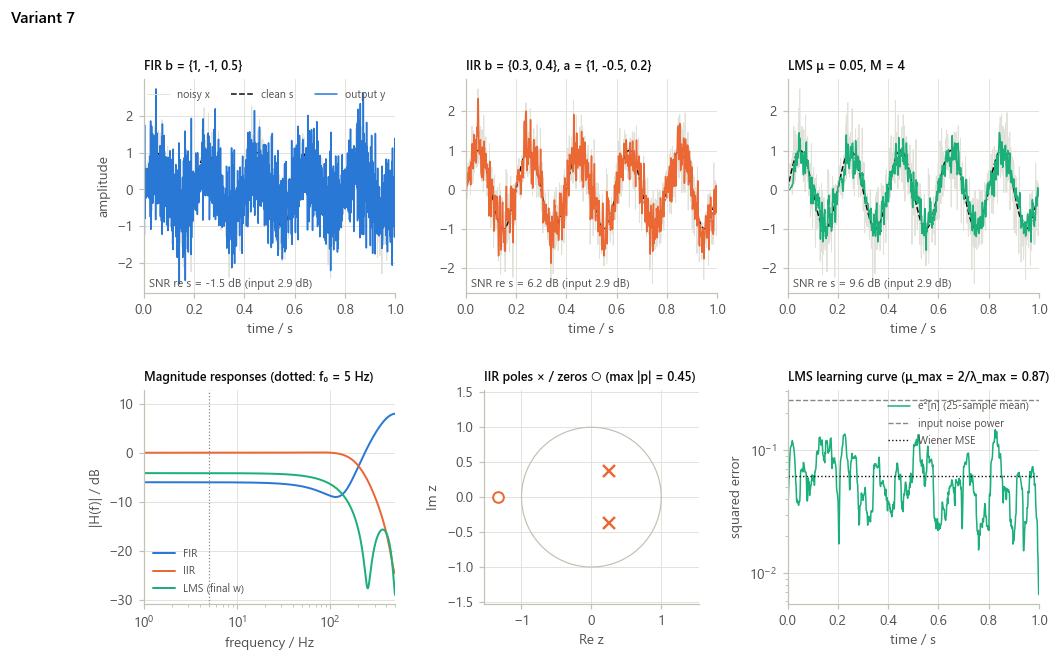

,type,|H(f₀)|,|H(0)|,|H(fs/2)|,noise gain Σh²,ΔSNR theory [dB],ΔSNR measured [dB],"MSE(y, s)",SNR re s [dB]
variant 7,,,,,,,,,
FIR,high-pass,0.5,0.5,2.5,2.25,-9.551,-9.495,0.698,-1.45
IIR,"low-pass, max|p| = 0.45",1.0,1.0,0.059,0.441,3.555,3.388,0.119,6.234
LMS,"adaptive, M = 4, μ = 0.05",,,,,,,0.055,9.553


LMS: final w = [0.13  0.15  0.162 0.177],  Wiener w_opt = [0.231 0.21  0.207 0.224],  MSE 0.0554 vs Wiener 0.0622,  μ = 0.05 < μ_max = 0.872


In [15]:
plot_variant(7)
variant_table(7)

### 5.8 Variant 8

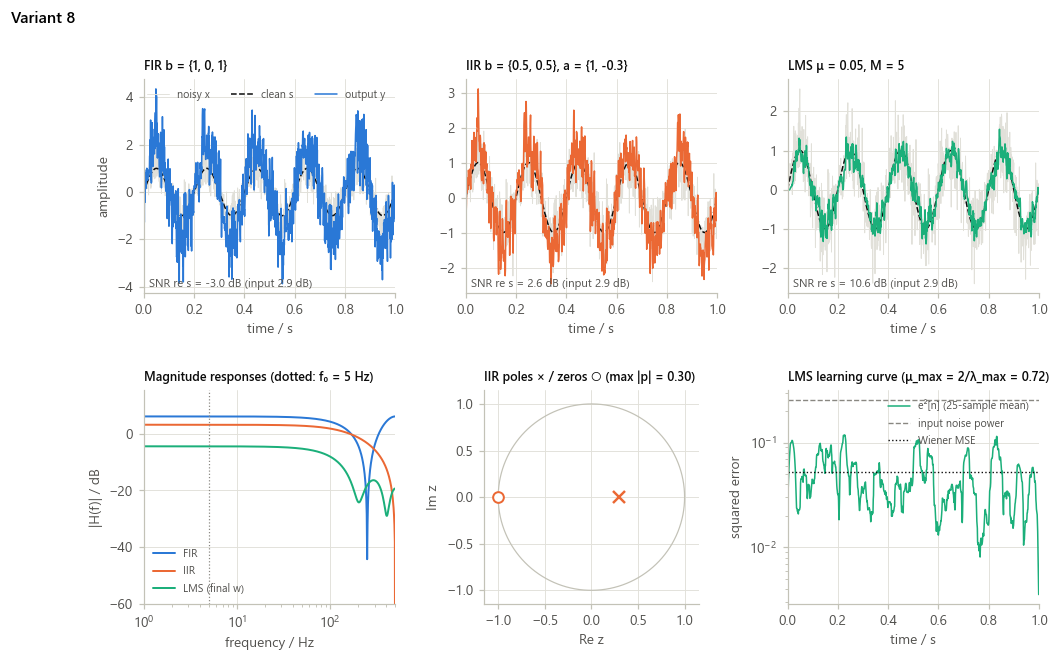

,type,|H(f₀)|,|H(0)|,|H(fs/2)|,noise gain Σh²,ΔSNR theory [dB],ΔSNR measured [dB],"MSE(y, s)",SNR re s [dB]
variant 8,,,,,,,,,
FIR,low-pass,1.999,2.0,2.0,2.0,3.006,2.919,1.009,-3.048
IIR,"low-pass, max|p| = 0.30",1.428,1.429,0.0,0.714,4.556,4.438,0.277,2.566
LMS,"adaptive, M = 5, μ = 0.05",,,,,,,0.044,10.595


LMS: final w = [0.09  0.107 0.116 0.138 0.147],  Wiener w_opt = [0.201 0.174 0.166 0.168 0.188],  MSE 0.0436 vs Wiener 0.0524,  μ = 0.05 < μ_max = 0.718


In [16]:
plot_variant(8)
variant_table(8)

### 5.9 Variant 9

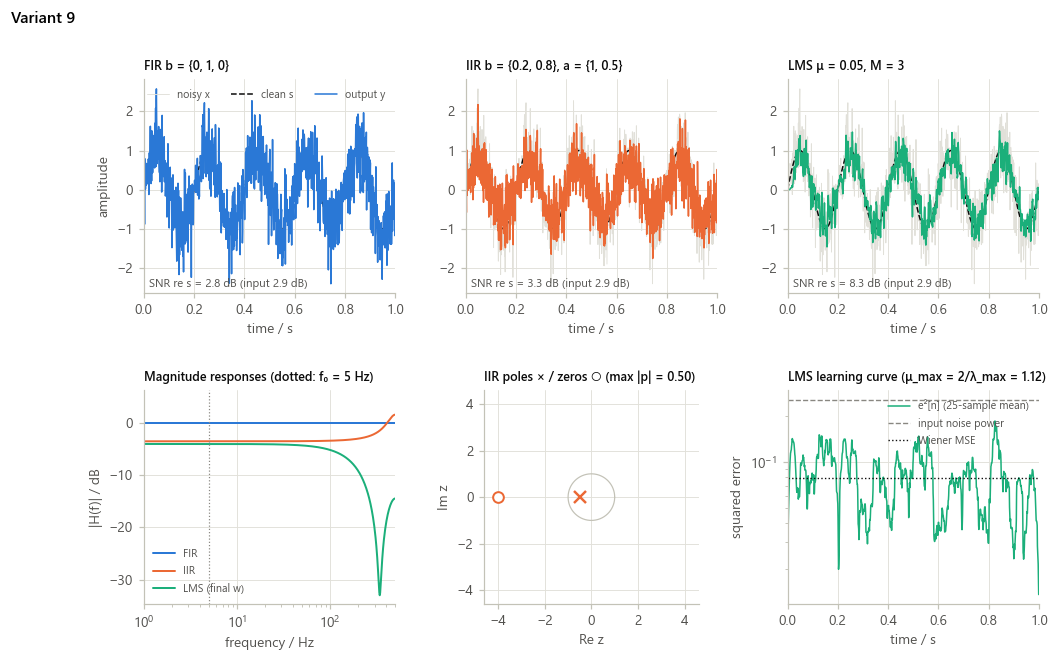

,type,|H(f₀)|,|H(0)|,|H(fs/2)|,noise gain Σh²,ΔSNR theory [dB],ΔSNR measured [dB],"MSE(y, s)",SNR re s [dB]
variant 9,,,,,,,,,
FIR,all-pass (gain/delay),1.0,1.0,1.0,1.0,0.0,-0.018,0.26,2.842
IIR,"high-pass, max|p| = 0.50",0.667,0.667,1.2,0.693,-1.931,-1.94,0.237,3.251
LMS,"adaptive, M = 3, μ = 0.05",,,,,,,0.074,8.309


LMS: final w = [0.191 0.22  0.218],  Wiener w_opt = [0.286 0.269 0.282],  MSE 0.0738 vs Wiener 0.0785,  μ = 0.05 < μ_max = 1.116


In [17]:
plot_variant(9)
variant_table(9)

### 5.10 Variant 10

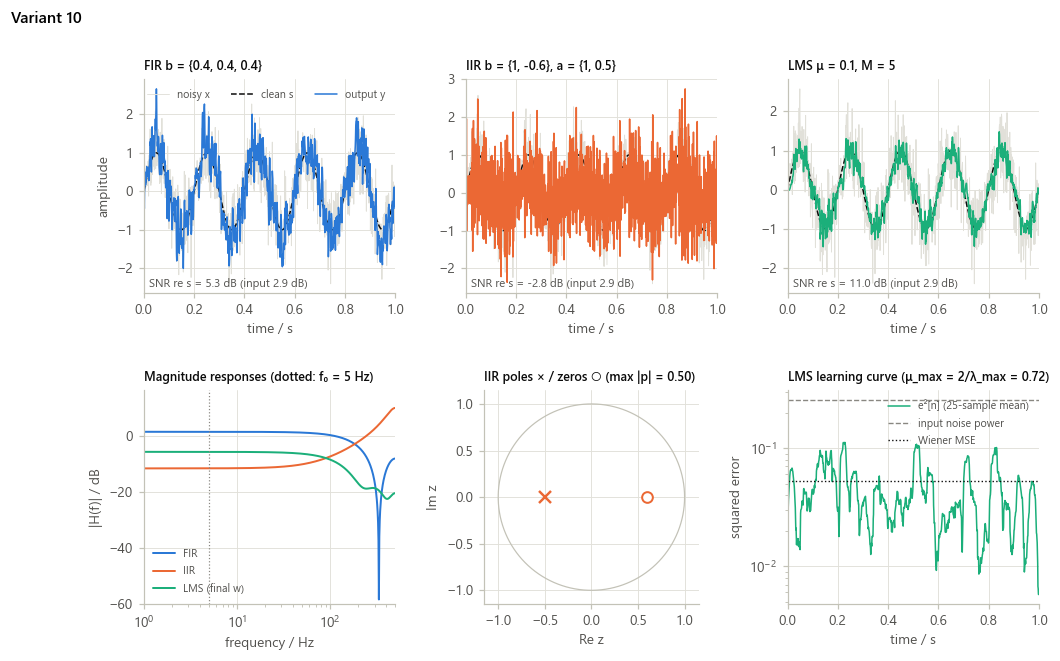

,type,|H(f₀)|,|H(0)|,|H(fs/2)|,noise gain Σh²,ΔSNR theory [dB],ΔSNR measured [dB],"MSE(y, s)",SNR re s [dB]
variant 10,,,,,,,,,
FIR,low-pass,1.2,1.2,0.4,0.48,4.768,4.604,0.148,5.286
IIR,"high-pass, max|p| = 0.50",0.267,0.267,3.2,2.613,-15.636,-15.661,0.945,-2.767
LMS,"adaptive, M = 5, μ = 0.1",,,,,,,0.04,10.99


LMS: final w = [0.038 0.071 0.111 0.144 0.163],  Wiener w_opt = [0.201 0.174 0.166 0.168 0.188],  MSE 0.0398 vs Wiener 0.0524,  μ = 0.1 < μ_max = 0.718


In [18]:
plot_variant(10)
variant_table(10)

### 5.11 Variant 11

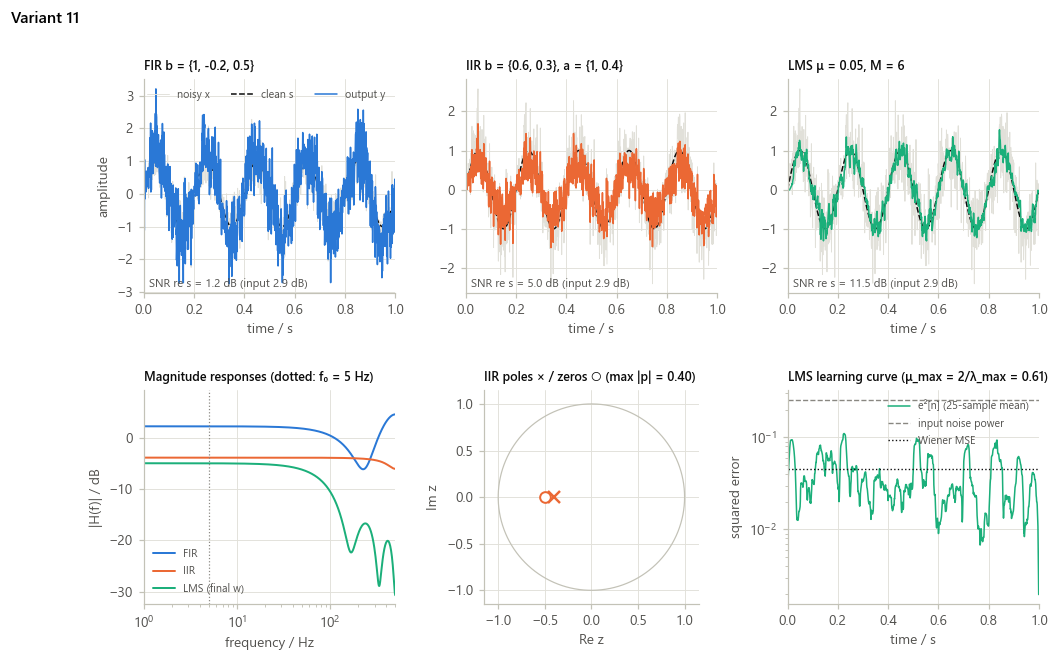

,type,|H(f₀)|,|H(0)|,|H(fs/2)|,noise gain Σh²,ΔSNR theory [dB],ΔSNR measured [dB],"MSE(y, s)",SNR re s [dB]
variant 11,,,,,,,,,
FIR,high-pass,1.299,1.3,1.7,1.29,1.169,1.139,0.376,1.235
IIR,"low-pass, max|p| = 0.40",0.643,0.643,0.5,0.364,0.548,0.545,0.16,4.96
LMS,"adaptive, M = 6, μ = 0.05",,,,,,,0.036,11.471


LMS: final w = [0.069 0.075 0.084 0.098 0.116 0.125],  Wiener w_opt = [0.171 0.159 0.143 0.14  0.148 0.151],  MSE 0.0356 vs Wiener 0.0459,  μ = 0.05 < μ_max = 0.610


In [19]:
plot_variant(11)
variant_table(11)

### 5.12 Variant 12

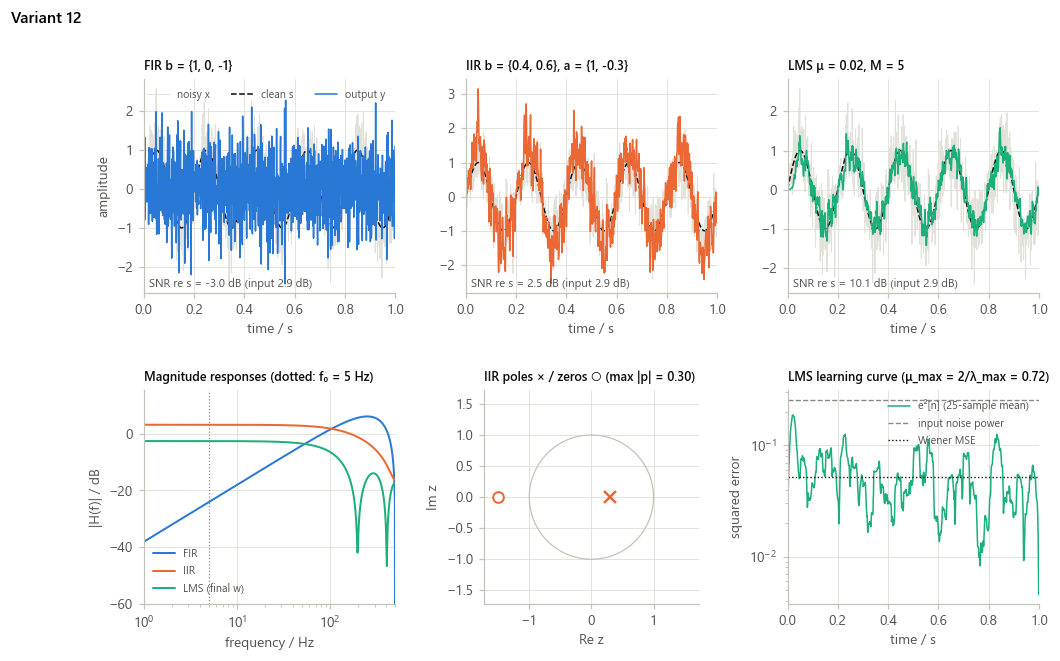

,type,|H(f₀)|,|H(0)|,|H(fs/2)|,noise gain Σh²,ΔSNR theory [dB],ΔSNR measured [dB],"MSE(y, s)",SNR re s [dB]
variant 12,,,,,,,,,
FIR,band-pass,0.063,0.0,0.0,2.0,-27.048,-26.98,1.003,-3.025
IIR,"low-pass, max|p| = 0.30",1.428,1.429,0.154,0.73,4.463,4.346,0.281,2.498
LMS,"adaptive, M = 5, μ = 0.02",,,,,,,0.048,10.144


LMS: final w = [0.147 0.149 0.137 0.152 0.154],  Wiener w_opt = [0.201 0.174 0.166 0.168 0.188],  MSE 0.0484 vs Wiener 0.0524,  μ = 0.02 < μ_max = 0.718


In [20]:
plot_variant(12)
variant_table(12)

### 5.13 Variant 13

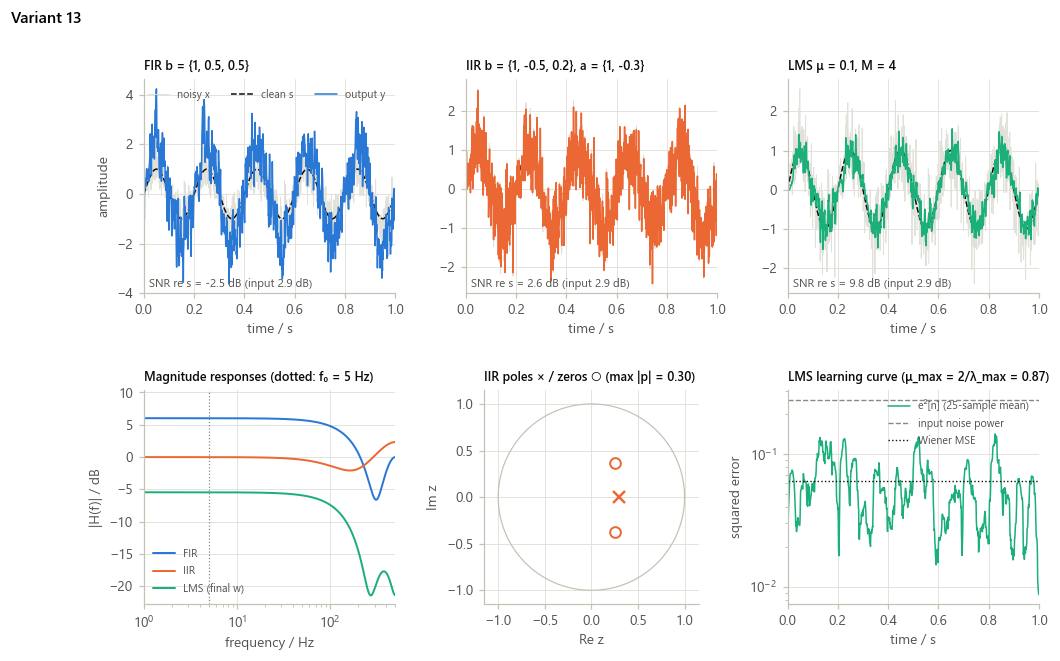

,type,|H(f₀)|,|H(0)|,|H(fs/2)|,noise gain Σh²,ΔSNR theory [dB],ΔSNR measured [dB],"MSE(y, s)",SNR re s [dB]
variant 13,,,,,,,,,
FIR,low-pass,1.999,2.0,1.0,1.5,4.257,4.124,0.881,-2.459
IIR,"high-pass, max|p| = 0.30",0.999,1.0,1.308,1.062,-0.264,-0.242,0.272,2.648
LMS,"adaptive, M = 4, μ = 0.1",,,,,,,0.052,9.828


LMS: final w = [0.072 0.127 0.152 0.183],  Wiener w_opt = [0.231 0.21  0.207 0.224],  MSE 0.0520 vs Wiener 0.0622,  μ = 0.1 < μ_max = 0.872


In [21]:
plot_variant(13)
variant_table(13)

### 5.14 Variant 14

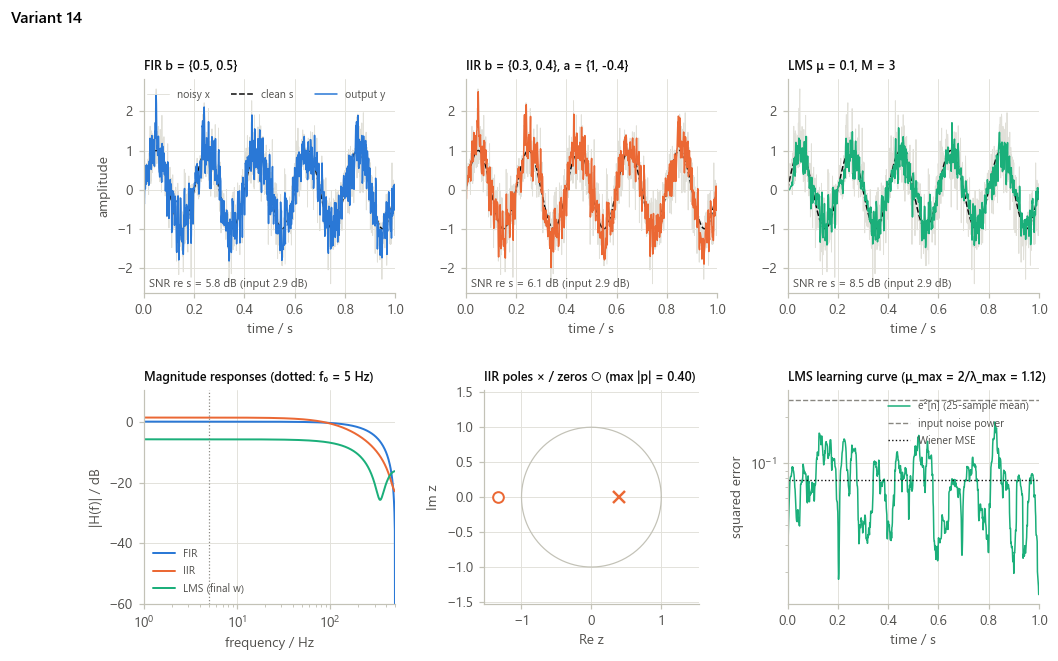

,type,|H(f₀)|,|H(0)|,|H(fs/2)|,noise gain Σh²,ΔSNR theory [dB],ΔSNR measured [dB],"MSE(y, s)",SNR re s [dB]
variant 14,,,,,,,,,
FIR,low-pass,1.0,1.0,0.0,0.5,3.009,2.928,0.132,5.795
IIR,"low-pass, max|p| = 0.40",1.166,1.167,0.071,0.412,5.185,5.065,0.124,6.07
LMS,"adaptive, M = 3, μ = 0.1",,,,,,,0.071,8.462


LMS: final w = [0.136 0.179 0.198],  Wiener w_opt = [0.286 0.269 0.282],  MSE 0.0712 vs Wiener 0.0785,  μ = 0.1 < μ_max = 1.116


In [22]:
plot_variant(14)
variant_table(14)

### 5.15 Variant 15

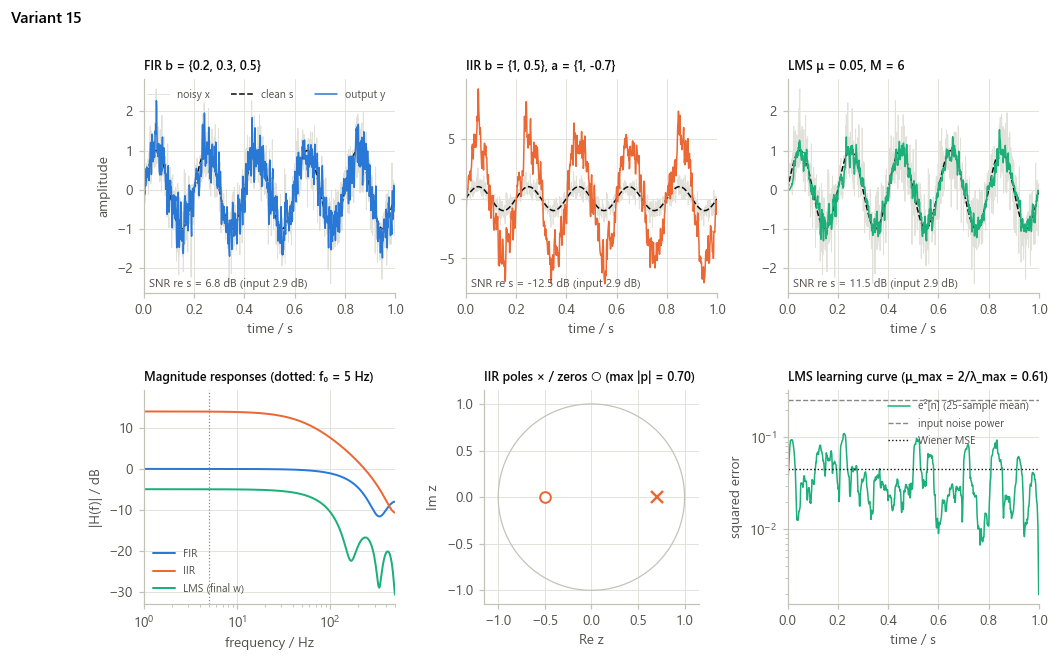

,type,|H(f₀)|,|H(0)|,|H(fs/2)|,noise gain Σh²,ΔSNR theory [dB],ΔSNR measured [dB],"MSE(y, s)",SNR re s [dB]
variant 15,,,,,,,,,
FIR,low-pass,1.0,1.0,0.4,0.38,4.2,4.056,0.104,6.839
IIR,"low-pass, max|p| = 0.70",4.98,5.0,0.294,3.824,8.121,7.964,8.792,-12.451
LMS,"adaptive, M = 6, μ = 0.05",,,,,,,0.036,11.471


LMS: final w = [0.069 0.075 0.084 0.098 0.116 0.125],  Wiener w_opt = [0.171 0.159 0.143 0.14  0.148 0.151],  MSE 0.0356 vs Wiener 0.0459,  μ = 0.05 < μ_max = 0.610


In [23]:
plot_variant(15)
variant_table(15)

### 5.16 Variant 16

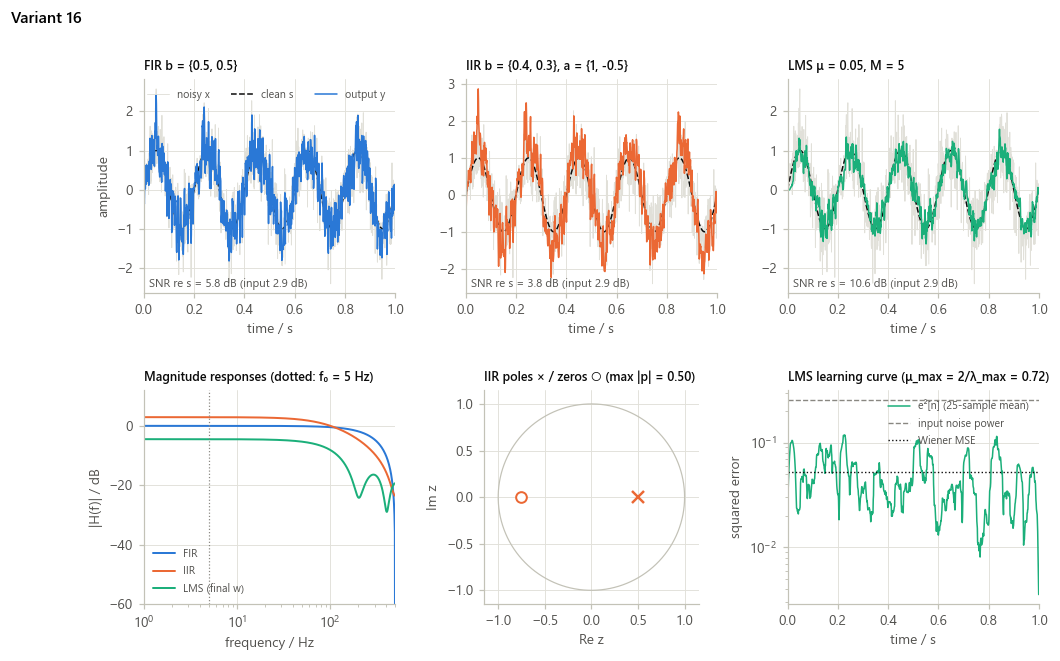

,type,|H(f₀)|,|H(0)|,|H(fs/2)|,noise gain Σh²,ΔSNR theory [dB],ΔSNR measured [dB],"MSE(y, s)",SNR re s [dB]
variant 16,,,,,,,,,
FIR,low-pass,1.0,1.0,0.0,0.5,3.009,2.928,0.132,5.795
IIR,"low-pass, max|p| = 0.50",1.398,1.4,0.067,0.493,5.982,5.863,0.209,3.798
LMS,"adaptive, M = 5, μ = 0.05",,,,,,,0.044,10.595


LMS: final w = [0.09  0.107 0.116 0.138 0.147],  Wiener w_opt = [0.201 0.174 0.166 0.168 0.188],  MSE 0.0436 vs Wiener 0.0524,  μ = 0.05 < μ_max = 0.718


In [24]:
plot_variant(16)
variant_table(16)

## 6. Comparison of all variants

In [25]:
SUM = pd.DataFrame([{
    "No": no,
    "FIR type": r["FIR"]["type"], "FIR |H(f₀)|": r["FIR"]["H_f0"], "FIR ΔSNR [dB]": r["FIR"]["dSNR_theory"],
    "FIR SNR re s [dB]": r["FIR"]["SNR_re_s"],
    "IIR type": r["IIR"]["type"], "IIR |H(f₀)|": r["IIR"]["H_f0"], "IIR ΔSNR [dB]": r["IIR"]["dSNR_theory"],
    "IIR SNR re s [dB]": r["IIR"]["SNR_re_s"],
    "LMS μ / M": f"{VARIANTS[no]['mu']:g} / {VARIANTS[no]['M']}", "LMS SNR re s [dB]": r["LMS"]["SNR_re_s"],
    "LMS / Wiener MSE": r["LMS"]["MSE"]/r["LMS"]["MSE_wiener"],
} for no, r in RES.items()]).set_index("No")
print(f"Input: SNR re s = {SNR_IN:.2f} dB (MSE = {MSE_IN:.4f}). ΔSNR = gain-independent improvement "
      "(white noise); 'SNR re s' = comparison of the output with the clean signal.")
display(SUM)

Input: SNR re s = 2.89 dB (MSE = 0.2569). ΔSNR = gain-independent improvement (white noise); 'SNR re s' = comparison of the output with the clean signal.


,FIR type,FIR |H(f₀)|,FIR ΔSNR [dB],FIR SNR re s [dB],IIR type,IIR |H(f₀)|,IIR ΔSNR [dB],IIR SNR re s [dB],LMS μ / M,LMS SNR re s [dB],LMS / Wiener MSE
No,,,,,,,,,,,
1,all-pass (gain/delay),1.000,0.000,2.791,high-pass,0.125,-27.085,-6.832,0.01 / 4,9.155,0.977
2,low-pass,3.999,4.257,-10.785,low-pass,3.466,9.827,-8.259,0.05 / 4,9.553,0.891
3,all-pass (gain/delay),3.000,0.000,-9.329,band-pass,0.588,-0.178,4.451,0.01 / 6,10.648,0.938
4,low-pass,0.700,4.595,7.279,low-pass,4.490,7.423,-11.421,0.1 / 4,9.828,0.837
5,low-pass,0.900,3.642,7.046,low-pass,1.250,4.365,4.327,0.05 / 4,9.553,0.891
6,low-pass,0.999,6.015,8.591,low-pass,5.992,6.899,-14.520,0.1 / 6,11.996,0.688
7,high-pass,0.500,-9.551,-1.450,low-pass,1.000,3.555,6.234,0.05 / 4,9.553,0.891
8,low-pass,1.999,3.006,-3.048,low-pass,1.428,4.556,2.566,0.05 / 5,10.595,0.832
9,all-pass (gain/delay),1.000,0.000,2.842,high-pass,0.667,-1.931,3.251,0.05 / 3,8.309,0.941


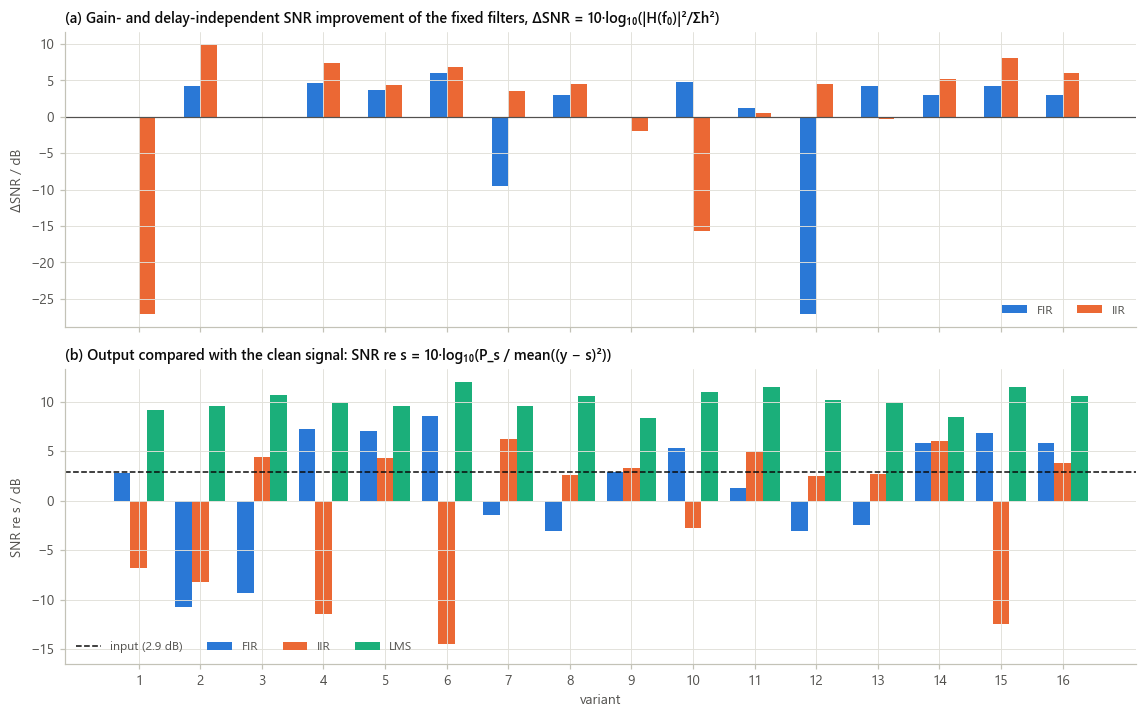

In [26]:
fig, axs = plt.subplots(2, 1, figsize=(10.5, 6.6), sharex=True)
nos = np.array(list(VARIANTS))
wbar = 0.27
ax = axs[0]
for j, key in enumerate(("FIR", "IIR")):
    ax.bar(nos + (j - 0.5)*wbar, [RES[n][key]["dSNR_theory"] for n in nos], wbar, color=COL[key], label=key)
ax.axhline(0, color=INK2, lw=0.8)
ax.set(ylabel="ΔSNR / dB")
ax.set_title("(a) Gain- and delay-independent SNR improvement of the fixed filters, ΔSNR = 10·log₁₀(|H(f₀)|²/Σh²)")
ax.legend(loc="lower right", ncols=2)
ax = axs[1]
for j, key in enumerate(("FIR", "IIR", "LMS")):
    ax.bar(nos + (j - 1)*wbar, [RES[n][key]["SNR_re_s"] for n in nos], wbar, color=COL[key], label=key)
ax.axhline(SNR_IN, color=INK, lw=1.0, ls="--", label=f"input ({SNR_IN:.1f} dB)")
ax.set(xlabel="variant", ylabel="SNR re s / dB", xticks=nos)
ax.set_title("(b) Output compared with the clean signal: SNR re s = 10·log₁₀(P_s / mean((y − s)²))")
ax.legend(loc="lower left", ncols=4)
lo = min(min(RES[n][k]["SNR_re_s"] for n in nos for k in ("FIR", "IIR", "LMS")), -5)
ax.set_ylim(max(lo - 2, -45), None)
fig.tight_layout()
save(fig, "fig18_comparison")

**LMS weights over time.** The figure compares a small step size (variant 1, μ = 0.01, M = 4) with a large one
(variant 6, μ = 0.1, M = 6); dashed lines are the Wiener weights w_opt computed from the whole record.

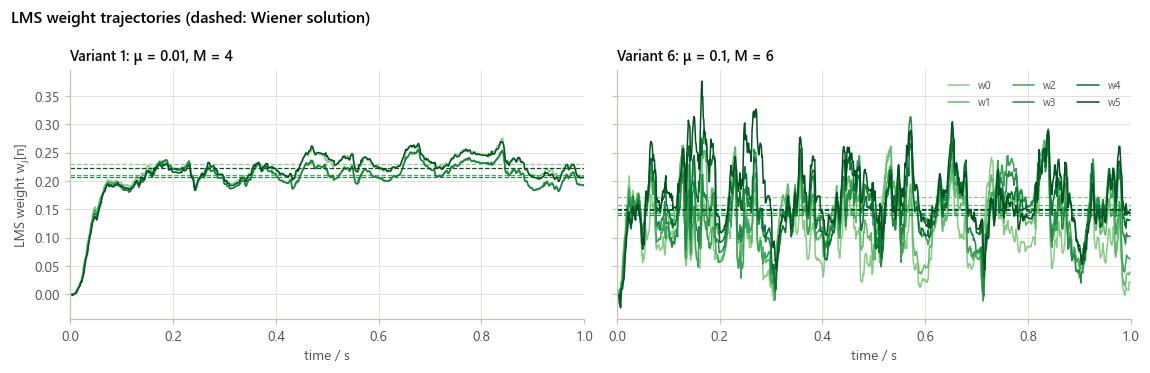

In [27]:
fig, axs = plt.subplots(1, 2, figsize=(10.5, 3.4), sharey=True)
for ax, no in zip(axs, (1, 6)):
    W, w_opt = RES[no]["LMS"]["W"], RES[no]["LMS"]["w_opt"]
    shades = plt.cm.Greens(np.linspace(0.45, 0.95, W.shape[1]))
    for j in range(W.shape[1]):
        ax.plot(t, W[:, j], color=shades[j], lw=1.0, label=f"w{j}")
        ax.axhline(w_opt[j], color=shades[j], lw=0.8, ls="--")
    ax.set_title(f"Variant {no}: μ = {VARIANTS[no]['mu']:g}, M = {VARIANTS[no]['M']}")
    ax.set_xlabel("time / s")
    ax.set_xlim(0, 1)
axs[0].set_ylabel("LMS weight wⱼ[n]")
axs[1].legend(loc="upper right", ncols=3, fontsize=7)
fig.suptitle("LMS weight trajectories (dashed: Wiener solution)", x=0.01, ha="left")
fig.tight_layout()
save(fig, "fig19_lms_weights")

In [28]:
# Checks of the statements made in the interpretation
snr = {k: np.array([RES[n][k]["SNR_re_s"] for n in VARIANTS]) for k in ("FIR", "IIR", "LMS")}
assert (snr["LMS"] > np.maximum(snr["FIR"], snr["IIR"])).all()                  # LMS best in every variant
assert all(RES[n]["LMS"]["MSE"] < MSE_IN for n in VARIANTS)                      # LMS always reduces the error
for n, p in VARIANTS.items():                                                    # FIR bound 10 log10(M)
    assert RES[n]["FIR"]["dSNR_theory"] <= 10*np.log10(len(p["b_fir"])) + 1e-6
assert np.isclose(RES[6]["FIR"]["dSNR_theory"], 10*np.log10(4), atol=0.01)       # moving average reaches it
by_M = {M: [RES[n]["LMS"]["SNR_re_s"] for n, p in VARIANTS.items() if p["M"] == M] for M in (3, 4, 5, 6)}
print("LMS SNR re s by filter length M:", {M: f"{min(v):.1f}–{max(v):.1f} dB" for M, v in by_M.items()})
print(f"LMS improvement over the input: {snr['LMS'].min() - SNR_IN:.1f} … {snr['LMS'].max() - SNR_IN:.1f} dB")
best_fixed = {k: int(np.array(list(VARIANTS))[np.argmax([RES[n][k]['dSNR_theory'] for n in VARIANTS])])
              for k in ("FIR", "IIR")}
print("largest ΔSNR: FIR variant", best_fixed["FIR"], f"({RES[best_fixed['FIR']]['FIR']['dSNR_theory']:.2f} dB),",
      "IIR variant", best_fixed["IIR"], f"({RES[best_fixed['IIR']]['IIR']['dSNR_theory']:.2f} dB)")
print("fixed filters that make the SNR worse (ΔSNR < 0): FIR", [n for n in VARIANTS if RES[n]["FIR"]["dSNR_theory"] < -0.01],
      "| IIR", [n for n in VARIANTS if RES[n]["IIR"]["dSNR_theory"] < -0.01])
print("fixed filters with SNR re s below the input: FIR", [n for n in VARIANTS if snr["FIR"][n-1] < SNR_IN],
      "| IIR", [n for n in VARIANTS if snr["IIR"][n-1] < SNR_IN])
print("LMS / Wiener MSE ratio:", f"{min(RES[n]['LMS']['MSE']/RES[n]['LMS']['MSE_wiener'] for n in VARIANTS):.2f} … "
      f"{max(RES[n]['LMS']['MSE']/RES[n]['LMS']['MSE_wiener'] for n in VARIANTS):.2f}")

LMS SNR re s by filter length M: {3: '8.3–8.5 dB', 4: '9.2–9.8 dB', 5: '10.1–11.0 dB', 6: '10.6–12.0 dB'}
LMS improvement over the input: 5.4 … 9.1 dB
largest ΔSNR: FIR variant 6 (6.02 dB), IIR variant 2 (9.83 dB)
fixed filters that make the SNR worse (ΔSNR < 0): FIR [7, 12] | IIR [1, 3, 9, 10, 13]
fixed filters with SNR re s below the input: FIR [1, 2, 3, 7, 8, 9, 11, 12, 13] | IIR [1, 2, 4, 6, 8, 10, 12, 13, 15]
LMS / Wiener MSE ratio: 0.69 … 0.98


**Effect of the gain.** Many of the given coefficient sets do not have unit gain at f₀. Dividing the output by
|H(f₀)| (b → b/|H(f₀)|) removes this error; what remains is the noise reduction ΔSNR and the small error caused
by the delay of the filter.

In [29]:
GAIN = pd.DataFrame({n: {
    "FIR |H(f₀)|": RES[n]["FIR"]["H_f0"], "FIR SNR re s": RES[n]["FIR"]["SNR_re_s"],
    "FIR SNR re s, gain corrected": snr_db(s[SS:], RES[n]["FIR"]["y"][SS:]/RES[n]["FIR"]["H_f0"] - s[SS:]),
    "IIR |H(f₀)|": RES[n]["IIR"]["H_f0"], "IIR SNR re s": RES[n]["IIR"]["SNR_re_s"],
    "IIR SNR re s, gain corrected": snr_db(s[SS:], RES[n]["IIR"]["y"][SS:]/RES[n]["IIR"]["H_f0"] - s[SS:]),
    "LMS SNR re s": RES[n]["LMS"]["SNR_re_s"]} for n in VARIANTS}).T.rename_axis("No")
print(f"SNR re s in dB (input {SNR_IN:.2f} dB):")
display(GAIN)

# key results for the report (scripts/make_report.py)
Path("results").mkdir(exist_ok=True)
OUT = SUM.join(GAIN[["FIR SNR re s, gain corrected", "IIR SNR re s, gain corrected"]])
OUT["IIR max|p|"] = [RES[n]["IIR"]["pole_radius"] for n in OUT.index]
OUT["LMS mu_max"] = [RES[n]["LMS"]["mu_max"] for n in OUT.index]
OUT.attrs["SNR_IN"] = SNR_IN
OUT.to_csv("results/summary.csv", encoding="utf-8")
pd.Series({"SNR_IN": SNR_IN, "MSE_IN": MSE_IN}).to_csv("results/input.csv", encoding="utf-8")
print("written: results/summary.csv, results/input.csv")

SNR re s in dB (input 2.89 dB):


,FIR |H(f₀)|,FIR SNR re s,"FIR SNR re s, gain corrected",IIR |H(f₀)|,IIR SNR re s,"IIR SNR re s, gain corrected",LMS SNR re s
No,,,,,,,
1,1.000,2.791,2.791,0.125,-6.832,-24.165,9.155
2,3.999,-10.785,6.897,3.466,-8.259,10.732,9.553
3,3.000,-9.329,2.791,0.588,4.451,2.722,10.648
4,0.700,7.279,7.244,4.490,-11.421,9.762,9.828
5,0.900,7.046,6.397,1.250,4.327,6.974,9.553
6,0.999,8.591,8.586,5.992,-14.520,9.304,11.996
7,0.500,-1.450,-6.603,1.000,6.234,6.235,9.553
8,1.999,-3.048,5.750,1.428,2.566,7.253,10.595
9,1.000,2.842,2.842,0.667,3.251,0.945,8.309


written: results/summary.csv, results/input.csv


## 7. Interpretation

**FIR filters.** At f₀ = 5 Hz ≪ fₛ the gain is H(f₀) ≈ Σbₖ, so ΔSNR ≈ 10·log₁₀((Σbₖ)²/Σbₖ²) ≤ 10·log₁₀(M) for M
taps (Cauchy–Schwarz), with equality only for equal coefficients. The 4-tap moving average of variant 6 reaches
this bound (6.02 dB, the best FIR); the other low-pass sets with positive coefficients (variants 2, 4, 5, 8, 10,
13–16) gain 3.0–4.8 dB. Filters with a single non-zero tap (variants 1, 9: pure delays; variant 3: delay × 3)
cannot average and leave the SNR unchanged (0 dB). Coefficients of alternating sign make high-pass or band-pass
filters that remove the signal instead of the noise: variant 7 {1, −1, 0.5} loses 9.6 dB and variant 12
{1, 0, −1} (zeros at z = ±1, i.e. at DC and fₛ/2) attenuates the 5 Hz tone to 0.063 and loses 27 dB.

**IIR filters.** All 16 IIR filters are stable (largest pole radius 0.8). A positive real pole 0 < p < 1 gives a
low-pass filter whose bandwidth shrinks as p → 1; for b₀/(1 − p·z⁻¹) the improvement is 10·log₁₀((1 + p)/(1 − p)),
i.e. 9.5 / 7.5 / 6.0 / 4.8 dB for p = 0.8 / 0.7 / 0.6 / 0.5, and the zeros of B(z) add or subtract a little. This
matches the best IIR filters: variant 2 (p = 0.8, ΔSNR = 9.8 dB, the best of all fixed filters), 15 (p = 0.7,
8.1 dB), 4 (p = 0.6, 7.4 dB) and 6, 16 (p = 0.5, 6.9 / 6.0 dB). With two or three coefficients the IIR filter
therefore does what an FIR filter needs about ten taps for (10·log₁₀ M ≥ 9.8 dB). Poles on the negative real axis
(variants 9, 10) or zeros close to z = 1 together with poles of negative real part (variant 1: zeros
0.75 ± 0.37j, poles −0.25 ± 0.19j) give high-pass filters and lose up to 27 dB.

**Gain and delay.** The ΔSNR values hold only up to a scale factor. Many given coefficient sets have
|H(f₀)| ≠ 1 (e.g. FIR {1, 1, 2}: 4; IIR variants 2, 4, 6, 15: 3.5–6), so their output is several times larger than
the clean signal and the direct comparison (SNR re s) is worse than the input, although the noise is reduced.
After dividing by |H(f₀)| the IIR filter of variant 2 reaches 10.7 dB and those of variants 4, 6 and 15
9.3–10.2 dB. FIR filters with symmetric or antisymmetric coefficients (e.g. variants 4, 6, 8, 9, 12, 14, 16) have
linear phase, i.e. a pure delay of (M − 1)/2 samples; the IIR filters have a non-linear phase, but at 5 Hz the delay of a few
milliseconds costs little.

**LMS filter.** In every variant the LMS filter gives the output closest to the clean signal: 8.3–12.0 dB, i.e.
5.4–9.1 dB better than the input, without any design. It finds the gain and a low-pass shape by itself (positive
weights, see the magnitude responses) and improves with the filter length (M = 3: 8.3–8.5 dB,
M = 4: 9.2–9.8 dB, M = 5: 10.1–11.0 dB, M = 6: 10.6–12.0 dB), consistent with the averaging gain 10·log₁₀(M).
All given step sizes are well below the stability limit 2/λ_max = 0.61–1.12. A small μ (0.01) needs about
0.1–0.15 s (100–150 samples) to reach the Wiener weights and then fluctuates only slightly. A large μ (0.1)
reaches them within about 10–20 ms, but the weights then fluctuate strongly around the Wiener solution
(gradient noise) and partly follow the local shape of the signal (Section 6, last figure). Because the desired
signal is the clean s, this time variation even makes the steady-state MSE 2–31 % smaller than that of the fixed
Wiener filter. Variants
with the same (μ, M), e.g. variants 2, 5 and 7, give identical LMS results because the input signal is the same.

**Caveat.** As in the example of the instructions, the LMS filter receives the clean signal as d[n]. In a real
noise-reduction task s is unknown. The LMS filter is then used as an adaptive noise canceller (d = noisy signal,
input = a reference correlated with the noise) or as an adaptive line enhancer (d = x[n], input x[n − Δ]). The
comparison therefore shows the best case for LMS; a well-designed fixed low-pass filter with the correct gain
(IIR variant 2) is just as good here (10.7 vs 9.6 dB for the LMS of the same variant).

## 8. Conclusions

1. FIR, IIR and LMS filters were implemented from the difference equations, validated against
   `scipy.signal.lfilter` and the Wiener solution, and applied to all 16 variants. Three defects in the example
   code of the instructions were corrected: the FIR start, the IIR slice lengths and the LMS input vector.
2. Only some of the given fixed filters reduce noise. Low-pass sets (positive FIR coefficients, IIR poles
   0 < p < 1) improve the SNR by up to 6.0 dB (FIR, bounded by 10·log₁₀ M) and 9.8 dB (IIR, pole 0.8). Pure delays
   do nothing, and high-pass or band-pass sets make the SNR worse (FIR variants 7, 12; IIR variants 1, 9, 10;
   up to −27 dB).
3. The gain at the signal frequency matters as much as the shape: without |H(f₀)| ≈ 1 the output is far from
   the clean signal even when the noise is reduced.
4. All IIR filters are stable. IIR filters reach a narrow low-pass with very few coefficients, while FIR filters
   are always stable and can have linear phase.
5. The LMS filter gives the best result in every variant (8.3–12.0 dB, +5.4 … +9.1 dB). It improves with M,
   and μ trades convergence speed against weight fluctuation. This advantage relies on knowing the clean signal
   as d[n].